not really anything useful here

Starting point to experiment with VAE


In [1]:
import sys
sys.path.append('../')

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

from src.models.vae import VAE

In [2]:
# load MNIST 
from torchvision import datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

batch_size = 128


transform = transforms.Compose([
    transforms.ToTensor(),
])


train_data = datasets.MNIST(
    '~/.pytorch/MNIST_data/',
    download=True,
    train=True,
    transform=transform,
)


test_data = datasets.MNIST(
    '~/.pytorch/MNIST_data/',
    download=True,
    train=False,
    transform=transform,
)


train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    drop_last=True,
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
)

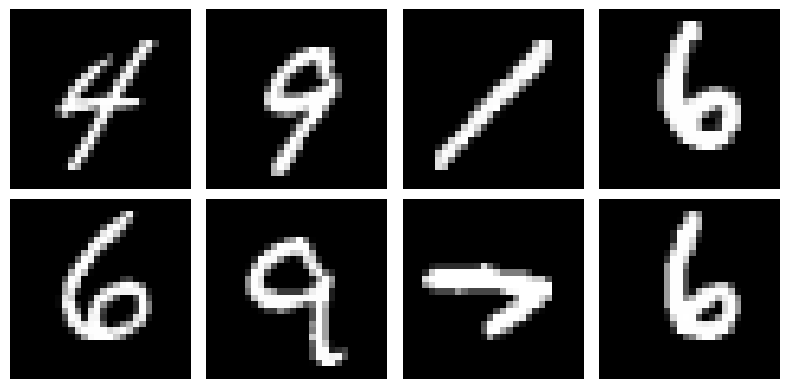

In [4]:

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
x = torch.rand(8, 1, 28, 28)
model = VAE(latent_dim=64)
out = model(x)
print(out.recon_x.shape)


torch.Size([8, 1, 28, 28])


In [5]:
device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')

vae = VAE().to(device)
print(f"VAE created with {sum(p.numel() for p in vae.parameters())} parameters")

images = images.to(device)

with torch.no_grad():
    output = vae(images[:8])

print(f"Total loss: {output.loss.item():.4f}")
print(f"Recon loss: {output.recon_loss.item():.4f}")
print(f"KL loss: {output.kl_loss.item():.4f}")

VAE created with 3021570 parameters
Total loss: 545.4491
Recon loss: 538.5829
KL loss: 6.8662


In [6]:
from tqdm import tqdm

vae = VAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

num_epochs = 3
max_batches_per_epoch = 50
losses = {'total': [], 'recon': [], 'kl': []}

vae.train()

for epoch in range(num_epochs):
    epoch_losses = {'total': 0, 'recon': 0, 'kl': 0}
    
    pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
    
    for batch_idx, (data, _) in enumerate(pbar):
        data = data.to(device)
        
        optimizer.zero_grad()
        output = vae(data)
        output.loss.backward()
        optimizer.step()
        
        epoch_losses['total'] += output.loss.item()
        epoch_losses['recon'] += output.recon_loss.item()
        epoch_losses['kl'] += output.kl_loss.item()
        
        if batch_idx >= max_batches_per_epoch:
            break
    
    num_batches = min(max_batches_per_epoch + 1, len(train_loader))
    for key in epoch_losses:
        epoch_losses[key] /= num_batches
        losses[key].append(epoch_losses[key])
    
    print(f'Epoch {epoch+1}: Total={epoch_losses["total"]:.3f}, '
          f'Recon={epoch_losses["recon"]:.3f}, KL={epoch_losses["kl"]:.3f}')

print("training completed")

Epoch 1/3:  11%|█         | 50/468 [00:18<02:35,  2.69it/s]


Epoch 1: Total=357.137, Recon=349.503, KL=7.635


Epoch 2/3:  11%|█         | 50/468 [00:16<02:20,  2.98it/s]


Epoch 2: Total=219.643, Recon=212.862, KL=6.781


Epoch 3/3:  11%|█         | 50/468 [00:16<02:21,  2.96it/s]

Epoch 3: Total=194.464, Recon=186.253, KL=8.210
training completed


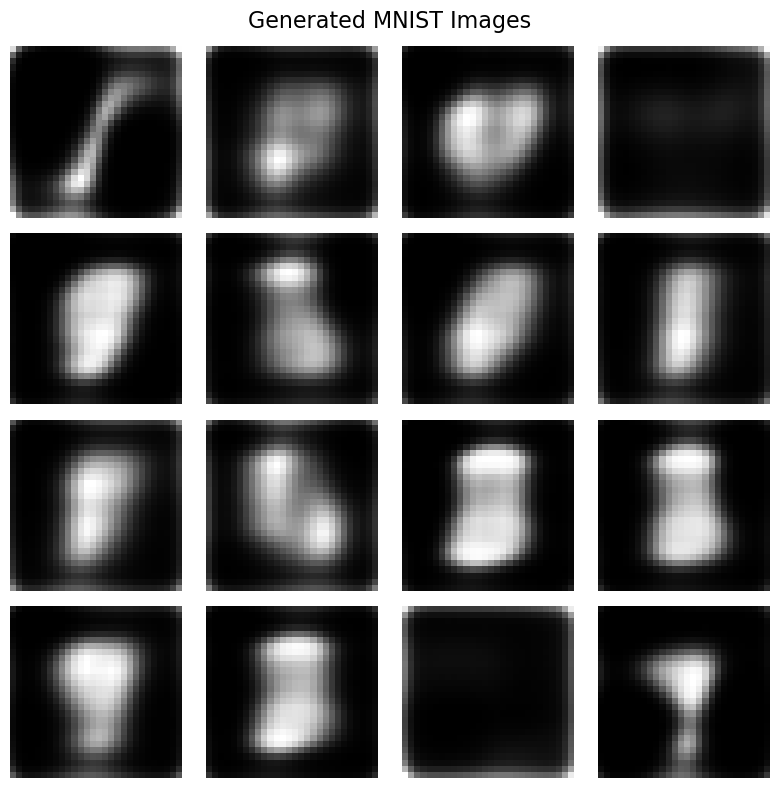

Generated 16 new images from random latent vectors!


In [7]:
import matplotlib.pyplot as plt

vae.eval()

num_samples = 16
with torch.no_grad():
    z = torch.randn(num_samples, 64, device=device)

    generated_images = vae.decode(z)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle('Generated MNIST Images', fontsize=16)

for i, ax in enumerate(axes.flat):
    img = generated_images[i].cpu().squeeze()
    ax.imshow(img, cmap='gray')
    ax.axis('off')

plt.tight_layout()
plt.show()

print(f"Generated {num_samples} new images from random latent vectors!")

In [2]:
import torch
from src.models.rdvae import RDVAE

x = torch.rand(8, 1, 28, 28)
model = RDVAE(latent_dim=64, R_target=2.0, gamma=100.0)
out = model(x)
print(out.loss.item(), out.recon_loss.item(), out.kl_loss.item())


RDVAE forward called
super.forward finished
548.4197998046875 543.4903564453125 6.929445266723633


/Users/phillip/repositories/vae-seminar/./src/data/
Checking if binarized_mnist_train.amat exists
/Users/phillip/repositories/vae-seminar/./src/data/
Checking if binarized_mnist_valid.amat exists
/Users/phillip/repositories/vae-seminar/./src/data/
Checking if binarized_mnist_test.amat exists


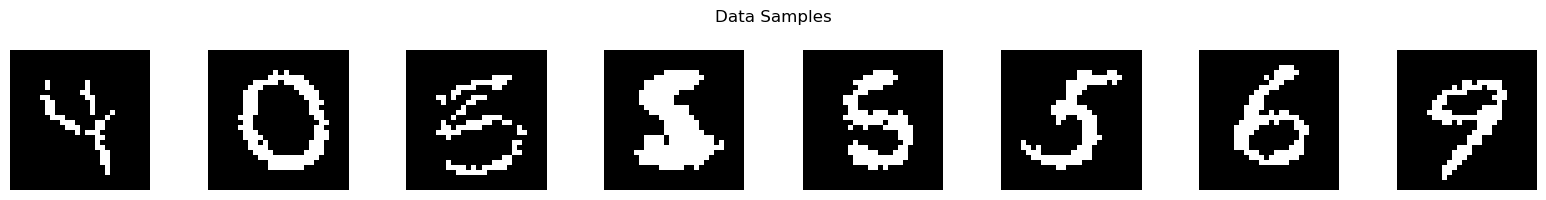

In [3]:
from src.utils.datasets import get_bin_mnist_loaders, visualize_batch

train_loader, val_loader, test_loader = get_bin_mnist_loaders(batch_size=128)
visualize_batch(train_loader)

In [ ]:
import torch
from src.models.rdvae import RDVAE
from src.utils.datasets import get_bin_mnist_loaders
from src.training.train_epoch import train_epoch, evaluate_epoch
import json
from tqdm import tqdm, trange

device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)



train_loader, val_loader, test_loader = get_bin_mnist_loaders(batch_size=128)

R_values = [0.5, 1.0, 2.0, 4.0, 8.0]
results = []

for R_target in R_values:
    print(f"\n=== Training RDVAE with R_target={R_target} ===")
    model = RDVAE(latent_dim=64, R_target=R_target, gamma=100.0).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    for epoch in trange(20, desc=f"R={R_target}"):
        train_stats = train_epoch(model, train_loader, optimizer, device)
        if epoch % 5 == 0:
            print(
                f"[{epoch:03d}] train_loss={train_stats['loss']:.2f} KL={train_stats['kl']:.2f} recon={train_stats['recon']:.2f}"
            )

    test_stats = evaluate_epoch(model, test_loader, device)
    test_stats["R_target"] = R_target
    results.append(test_stats)

with open("rd_results.json", "w") as f:
    json.dump(results, f, indent=4)


/Users/phillip/repositories/vae-seminar/./src/data/
Checking if binarized_mnist_train.amat exists
/Users/phillip/repositories/vae-seminar/./src/data/
Checking if binarized_mnist_valid.amat exists
/Users/phillip/repositories/vae-seminar/./src/data/
Checking if binarized_mnist_test.amat exists

=== Training RDVAE with R_target=0.5 ===


R=0.5:   5%|▌         | 1/20 [02:27<46:35, 147.16s/it]

[000] train_loss=264.97 KL=7.63 recon=257.85


R=0.5:  30%|███       | 6/20 [13:47<30:56, 132.63s/it]

[005] train_loss=160.80 KL=11.53 recon=149.77


...

[015] train_loss=138.23 KL=17.79 recon=120.94


R=0.5: 100%|██████████| 20/20 [2:10:47<00:00, 392.39s/it]   



=== Training RDVAE with R_target=1.0 ===


R=1.0:   0%|          | 0/20 [00:00<?, ?it/s]

: 